# Otimização de CNN1D Quantizada para FPGA (ATLAS L0 Ringer)
## Alocação de Bits por Lagrange/KKT, Topologia v2 (25 Anéis) e Estrutura de Exportação Jubiaba

Este notebook implementa o pipeline completo de codesign hardware-software para o sistema de filtragem online do ATLAS L0 Ringer, organizando todos os artefatos gerados de acordo com a especificação hierárquica do projeto **Jubiaba**:

```text
<export_dir>/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/
├── saved_models/  # Todos os modelos por fold (model_v{V}_f{F}_r{R}.keras), best_model.keras, best_model.onnx
├── plots/         # Perfis de anéis, curvas de aprendizado, curvas ROC, matriz de confusão, boxplots CV e Pareto
├── history/       # Histórico da melhor execução em CSV e JSON
├── metadata/      # training_metadata_v{V}.pkl/.json, cross_validation_results.csv, reproducibility_metadata.json
└── evaluation/    # Splits de holdout comprimidos (holdout_test_set.npz) e predições (holdout_predictions.npz)
```

### Destaques desta Execução:
1. **Suporte Facilitado a Múltiplas Resoluções (`v0`, `v1`, `v2`)**: Basta alterar `version = 2` (25 anéis), `version = 1` (50 anéis) ou `version = 0` (100 anéis) na célula de configuração;
2. **Alocação Heterogênea de Bits por Lagrange e Condições KKT**: Cálculo estocástico do traço da Hessiana $\operatorname{Tr}(\mathbf{H}_i)$ via algoritmo de Hutchinson e solução analítica *water-filling*;
3. **Validação Cruzada Estratificada ($K$-Folds) + Holdout**: Avaliação estatística rigorosa com todas as visualizações do `codeTCC`;
4. **Fronteira de Pareto Multi-Objetivo (NSGA-II)**: Mapeamento do *trade-off* entre o Índice Soma-Produto ($SP$) e o custo de hardware ($\text{BOPs}$).


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
import qkeras
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_curve, auc

# Adicionar raiz do repositório ao PYTHONPATH
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.metrics import (
    ESTRUTURA_BASE,
    CONFIG_VERSOES,
    slice_rings_by_version,
    norm1,
    compute_sp,
    compute_sp_with_threshold,
    SPCallback,
)
from src.hardware import compute_model_hardware_costs
from src.kkt_allocator import (
    compute_hutchinson_hessian_trace,
    compute_layer_c_coefficients,
    solve_kkt_bit_allocation,
)
from src.models import build_compact_cnn1d_fp32, build_compact_qcnn1d
from src.exporter import ArtifactExporter
from src.visualization import (
    plot_rings_profile,
    plot_learning_curves,
    plot_best_model_roc,
    plot_cv_roc_envelope,
    plot_output_score_histogram,
    plot_confusion_matrix_knee,
    plot_cv_statistics_boxplots,
    plot_fa_per_fold_workpoints,
    plot_pareto_and_roc_duel,
)

# Sementes para reprodutibilidade científica
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("QKeras Version:", qkeras.__version__)
print("Repository Root:", repo_root)


2026-11-07 00:58:05.346206: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-07 00:58:05.346488: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-07 00:58:05.378255: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-07 00:58:06.211504: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-07 00:58:06.211781: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.20.0
QKeras Version: 0.9.0
Repository Root: /home/iaraujo/Documentos/Github/cnn-optimization


## 1. Configuração da Região Cinemática, Versão dos Anéis (`v2` = 25 Anéis) e Exportador Jubiaba

Para alternar entre as topologias do calorímetro:
- `version = 0`: **100 anéis** (Resolução original completa: `PS:8, EM1:64, EM2:8, EM3:8, HAD1:4, HAD2:4, HAD3:4`)
- `version = 1`: **50 anéis** (Fator de redução 2x: `PS:4, EM1:32, EM2:4, EM3:4, HAD1:2, HAD2:2, HAD3:2`)
- `version = 2`: **25 anéis** (Fator de redução 4x: `PS:2, EM1:16, EM2:2, EM3:2, HAD1:1, HAD2:1, HAD3:1`)

O fatiamento preserva os anéis internos mais próximos ao baricentro da cascata eletromagnética, onde se concentra a maior relação sinal-ruído.


In [2]:
# ==============================================================================
# PARÂMETROS GLOBAIS DO EXPERIMENTO (FÁCIL ALTERAÇÃO)
# ==============================================================================
EXPORT_DIR = os.path.join(repo_root, "results")
DATASET_PREFIX = "mc21_13p6TeV.Zee.JF17.2sigma.5M"
MODEL_NAME = "QCNN1D_KKT"
IET = 5
IETA = 0
VERSION = 2        # <--- 0 (100 anéis), 1 (50 anéis), ou 2 (25 anéis)
N_SPLITS = 5       # Número de folds na validação cruzada
EPOCHS_CV = 15     # Épocas por fold

cfg_versao = CONFIG_VERSOES[VERSION]
input_dim = cfg_versao["input_dim"]
kernel_size = cfg_versao["kernel"]
num_filters = cfg_versao["filters"]
dense_units = cfg_versao["dense_units"]

# Inicializa o Exportador Hierárquico padrão Jubiaba
exporter = ArtifactExporter(
    export_dir=EXPORT_DIR,
    dataset_prefix=DATASET_PREFIX,
    model_name=MODEL_NAME,
    iet=IET,
    ieta=IETA,
    version=VERSION,
)

print(f"Diretório Base de Exportação (Jubiaba):\n  -> {exporter.base_dir}")
print(f"Configuração da Versão v{VERSION}: {input_dim} anéis | Kernel={kernel_size} | Filters={num_filters} | Dense={dense_units}")


Diretório Base de Exportação (Jubiaba):
  -> /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2
Configuração da Versão v2: 25 anéis | Kernel=3 | Filters=8 | Dense=8


## 2. Ingestão dos Dados, Normalização L1 e Perfil Médio de Energia por Camada

Carregamos o arquivo HDF5 da região cinemática $(\text{iet}=5, \text{ieta}=0)$, aplicamos a normalização L1 por evento e reduzimos a matriz de entrada para a versão selecionada (`v2` = 25 anéis) utilizando `slice_rings_by_version`.


Carregando dados de: /home/iaraujo/Documentos/Github/cnn-optimization/data/mc21_13p6TeV.Zee.JF17.2sigma.5M.et5_eta0.h5


Total de amostras balanceadas: 77,126 (38,563 Elétrons / 38,563 Jatos)
Estrutura das camadas do calorímetro em v2 (25 anéis): {'PS': 2, 'EM1': 16, 'EM2': 2, 'EM3': 2, 'HAD1': 1, 'HAD2': 1, 'HAD3': 1}


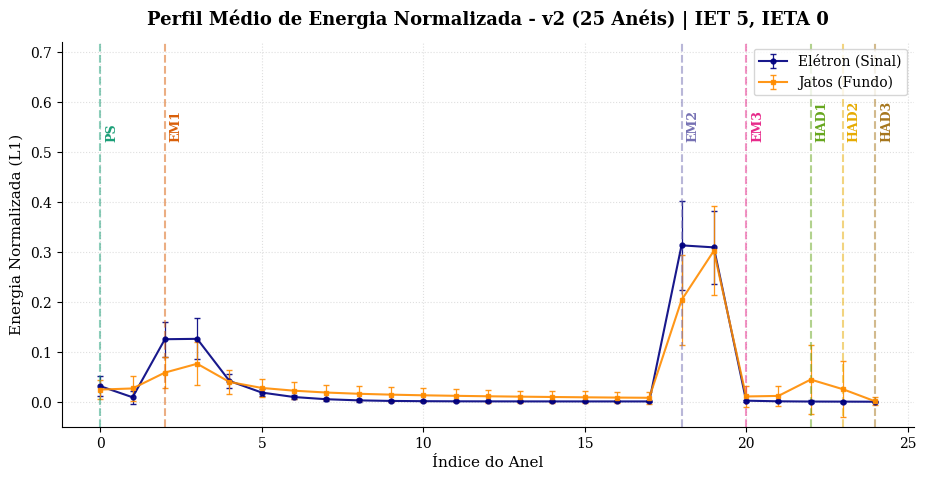

Gráfico de perfil de anéis salvo em: /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/plots/rings_profile_v2.png
Conjunto de Desenvolvimento (CV): (61700, 25) | Conjunto Holdout de Teste: (15426, 25)


In [3]:
data_path = os.path.join(repo_root, "data", f"{DATASET_PREFIX}.et{IET}_eta{IETA}.h5")
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Dataset não encontrado em: {data_path}")

print(f"Carregando dados de: {data_path}")
df_loaded = pd.read_hdf(data_path, key="data")

ring_columns = [col for col in df_loaded.columns if col.startswith("trig_L2_cl_ring_")]
ring_columns = sorted(ring_columns, key=lambda x: int(x.split("_")[-1]))

signal_df = df_loaded[df_loaded["target"] == 1][ring_columns]
background_df = df_loaded[df_loaded["target"] == 0][ring_columns]

ns = min(len(signal_df), len(background_df))
print(f"Total de amostras balanceadas: {ns * 2:,} ({ns:,} Elétrons / {ns:,} Jatos)")

# Fatiamento por versão (v0=100, v1=50, v2=25) seguido de normalização L1 na janela selecionada
sig_sliced, estrutura_v = slice_rings_by_version(signal_df.values[:ns], VERSION)
bkg_sliced, _ = slice_rings_by_version(background_df.values[:ns], VERSION)

sig_normed = norm1(sig_sliced)
bkg_normed = norm1(bkg_sliced)

print(f"Estrutura das camadas do calorímetro em v{VERSION} ({input_dim} anéis): {estrutura_v}")

# Visualização 1: Perfil Médio dos Anéis (Estilo codeTCC)
profile_plot_path = exporter.get_plot_path(f"rings_profile_v{VERSION}.png")
plot_rings_profile(
    sig_normed=sig_normed,
    bkg_normed=bkg_normed,
    estrutura=estrutura_v,
    version=VERSION,
    iet=IET,
    ieta=IETA,
    save_path=profile_plot_path,
    show=True,
)
print(f"Gráfico de perfil de anéis salvo em: {profile_plot_path}")

# Montagem do Dataset Completo e Separação de Holdout de Teste (20%) + Desenvolvimento CV (80%)
X_all = np.vstack([sig_normed, bkg_normed]).astype(np.float32)
y_all = np.concatenate([np.ones(ns, dtype=np.float32), np.zeros(ns, dtype=np.float32)])

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED
)
print(f"Conjunto de Desenvolvimento (CV): {X_dev.shape} | Conjunto Holdout de Teste: {X_holdout.shape}")


## 3. Baseline FP32 e Alocação Analítica de Bits via Lagrange / KKT

Treinamos o modelo compacto em precisão simples (FP32) para estimar a sensibilidade de 2ª ordem de cada camada via algoritmo estocástico de Hutchinson:

$$\operatorname{Tr}(\mathbf{H}_i) \approx \frac{1}{m} \sum_{j=1}^m \mathbf{z}_j^T (\mathbf{H}_i \mathbf{z}_j), \quad \mathbf{z}_j \in \{-1, +1\}^{n_i}$$

Em seguida, resolvemos o problema de alocação ótima de bits sob restrição de orçamento de operações binárias ($\text{BOPs}$):

$$b_i^*(\lambda) = \min\left( b_{\max}, \max\left( b_{\min}, \frac{1}{2} \log_2 \left( \frac{c_i \ln 4}{\lambda a_i} \right) \right) \right)$$


In [4]:
# Split de referência para calibração da Hessiana e Baseline FP32
X_tr_ref, X_val_ref, y_tr_ref, y_val_ref = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED
)

model_fp32 = build_compact_cnn1d_fp32(
    input_dim=input_dim,
    num_filters=num_filters,
    kernel_size=kernel_size,
    dense_units=dense_units,
)
sp_cb_fp32 = SPCallback(val_data=(X_val_ref, y_val_ref), patience=8, verbose=True)

history_fp32 = model_fp32.fit(
    X_tr_ref, y_tr_ref,
    validation_data=(X_val_ref, y_val_ref),
    epochs=EPOCHS_CV,
    batch_size=512,
    callbacks=[sp_cb_fp32],
    verbose=1,
)
sp_cb_fp32.restore_best_weights()
hw_fp32 = compute_model_hardware_costs(model_fp32, input_dim=input_dim)

# Avaliação do FP32 no Holdout
y_pred_fp32_holdout = model_fp32.predict(X_holdout, batch_size=2048, verbose=0).ravel()
sp_fp32_ho, pd_fp32_ho, fa_fp32_ho, thresh_fp32_ho, _ = compute_sp_with_threshold(y_holdout, y_pred_fp32_holdout)
print(f"\n[Baseline FP32 Holdout] SP = {sp_fp32_ho:.4f} | PD = {pd_fp32_ho*100:.2f}% | FA = {fa_fp32_ho*100:.2f}% | MACs = {hw_fp32['total_macs']:,}")

# Estimativa do Traço da Hessiana (Hutchinson) e Solução KKT
sample_idx = np.random.choice(len(X_val_ref), size=512, replace=False)
x_sample_tf = tf.convert_to_tensor(X_val_ref[sample_idx])
y_sample_tf = tf.convert_to_tensor(y_val_ref[sample_idx], dtype=tf.float32)[:, None]
bce_loss = keras.losses.BinaryCrossentropy()

traces = compute_hutchinson_hessian_trace(model_fp32, bce_loss, x_sample_tf, y_sample_tf, num_hvp=10, seed=SEED)
c_coeffs = compute_layer_c_coefficients(model_fp32, traces)

layer_names = [item["layer_name"] for item in hw_fp32["breakdown"]]
a_costs = [item["macs"] * item["b_a"] for item in hw_fp32["breakdown"]]
c_list = [c_coeffs[name] for name in layer_names]

bops_uniform_8bit = sum(a * 8 for a in a_costs)
budget_target = bops_uniform_8bit * 0.60  # Meta: 40% de economia em BOPs frente a 8-bit uniforme

kkt_result = solve_kkt_bit_allocation(
    layer_names=layer_names,
    c_coeffs=c_list,
    a_costs=a_costs,
    budget_bops=budget_target,
    b_min=2,
    b_max=8,
)
kkt_weights_bits = kkt_result["integer_bits"]

print("\n=== Alocação Analítica de Bits por Camada (KKT Water-Filling) ===")
for name in layer_names:
    idx_l = layer_names.index(name)
    print(
        f"  • {name:14s} | Tr(H)={traces[name]:.3e} | c_i={c_coeffs[name]:.3e} "
        f"| a_i={a_costs[idx_l]:5.0f} | b*={kkt_result['continuous_bits'][name]:.2f} -> {kkt_weights_bits[name]} bits"
    )
print(f"BOPs 8-bit Uniforme: {bops_uniform_8bit:,.0f} -> BOPs KKT Alocado: {kkt_result['achieved_bops']:,.0f} ({kkt_result['achieved_bops']/bops_uniform_8bit*100:.1f}%)")


Epoch 1/15


2026-11-07 00:58:07.673908: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


 1/97 [..............................] - ETA: 32s - loss: 0.6913 - accuracy: 0.6406

35/97 [=========>....................] - ETA: 0s - loss: 0.6820 - accuracy: 0.5815 

73/97 [=====================>........] - ETA: 0s - loss: 0.6683 - accuracy: 0.7000


[SPCallback] Epoch 1: New best SP = 0.9265 (PD=0.9679, FA=0.1141, Thresh=0.5118)
97/97 [==============================] - 1s 4ms/step - loss: 0.6564 - accuracy: 0.7477 - val_loss: 0.5999 - val_accuracy: 0.9159 - val_sp: 0.9265 - val_pd_knee: 0.9679 - val_fa_knee: 0.1141


... (68 outputs left out)

81/97 [========================>.....] - ETA: 0s - loss: 0.0919 - accuracy: 0.9709


[SPCallback] Epoch 15: New best SP = 0.9749 (PD=0.9862, FA=0.0363, Thresh=0.6060)
97/97 [==============================] - 0s 2ms/step - loss: 0.0916 - accuracy: 0.9710 - val_loss: 0.0884 - val_accuracy: 0.9728 - val_sp: 0.9749 - val_pd_knee: 0.9862 - val_fa_knee: 0.0363



[Baseline FP32 Holdout] SP = 0.9739 | PD = 98.11% | FA = 3.33% | MACs = 1,376



=== Alocação Analítica de Bits por Camada (KKT Water-Filling) ===
  • conv1d_1       | Tr(H)=4.490e+00 | c_i=6.485e+01 | a_i= 4800 | b*=3.43 -> 3 bits
  • dense_1        | Tr(H)=6.775e+00 | c_i=2.417e+03 | a_i= 6144 | b*=5.87 -> 6 bits
  • output_dense   | Tr(H)=6.854e-01 | c_i=5.471e+00 | a_i=   64 | b*=4.77 -> 8 bits
BOPs 8-bit Uniforme: 88,064 -> BOPs KKT Alocado: 51,776 (58.8%)


## 4. Validação Cruzada Estratificada ($K=5$ Folds) do Modelo QKeras KKT e Salvamento Hierárquico

Treinamos o modelo `QCNN1D_KKT` com a precisão mista encontrada por KKT ao longo de 5 folds estratificados, salvando cada modelo individual em `saved_models/model_v{V}_f{F}_r1.keras`, identificando o melhor fold e avaliando-o no conjunto Holdout isolado.


In [5]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

training_results_metadata = []
cv_records = []
folds_y_true = []
folds_y_pred = []

best_overall_sp = -1.0
best_fold_idx = 1
best_qmodel = None
best_history_dict = None
best_val_threshold = 0.5

print(f"Iniciando {N_SPLITS}-Fold Cross-Validation para QCNN1D_KKT (v{VERSION} - {input_dim} anéis)...")

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    X_tr_f, y_tr_f = X_dev[tr_idx], y_dev[tr_idx]
    X_val_f, y_val_f = X_dev[val_idx], y_dev[val_idx]

    qmodel_f = build_compact_qcnn1d(
        input_dim=input_dim,
        num_filters=num_filters,
        kernel_size=kernel_size,
        dense_units=dense_units,
        weights_bits=kkt_weights_bits,
        act_bits=8,
        learning_rate=1e-3,
    )

    sp_cb_f = SPCallback(val_data=(X_val_f, y_val_f), patience=8, verbose=False)
    hist_f = qmodel_f.fit(
        X_tr_f, y_tr_f,
        validation_data=(X_val_f, y_val_f),
        epochs=EPOCHS_CV,
        batch_size=512,
        callbacks=[sp_cb_f],
        verbose=0,
    )
    sp_cb_f.restore_best_weights()

    # Salvar modelo do fold na estrutura Jubiaba
    fold_model_path = exporter.save_fold_model(qmodel_f, fold=fold_idx, repeat=1)

    # Predições na validação do fold
    y_val_pred = qmodel_f.predict(X_val_f, batch_size=2048, verbose=0).ravel()
    sp_f, pd_f, fa_f, thresh_f, knee_idx = compute_sp_with_threshold(y_val_f, y_val_pred)
    fa_curve, pd_curve, _ = roc_curve(y_val_f, y_val_pred)
    auc_f = float(auc(fa_curve, pd_curve))

    folds_y_true.append(y_val_f)
    folds_y_pred.append(y_val_pred)

    cv_records.append({
        "fold": fold_idx,
        "repeat": 1,
        "sp_max": sp_f,
        "pd_knee": pd_f,
        "fa_knee": fa_f,
        "threshold_knee": thresh_f,
        "auc": auc_f,
        "best_epoch": sp_cb_f.best_epoch + 1,
        "model_path": os.path.basename(fold_model_path),
    })

    training_results_metadata.append({
        "fold": fold_idx,
        "repeat": 1,
        "max_sp": sp_f,
        "pd_knee": pd_f,
        "fa_knee": fa_f,
        "threshold_knee": thresh_f,
        "auc": auc_f,
        "best_epoch": sp_cb_f.best_epoch + 1,
        "keras_history": hist_f.history,
    })

    print(
        f"  [Fold {fold_idx}/{N_SPLITS}] SP = {sp_f*100:.2f}% | PD = {pd_f*100:.2f}% "
        f"| FA = {fa_f*100:.2f}% | AUC = {auc_f:.4f} | Salvo: {os.path.basename(fold_model_path)}"
    )

    if sp_f > best_overall_sp:
        best_overall_sp = sp_f
        best_fold_idx = fold_idx
        best_qmodel = qmodel_f
        best_history_dict = hist_f.history
        best_val_threshold = thresh_f

cv_df = pd.DataFrame(cv_records)
print(f"\nMelhor Fold: #{best_fold_idx} com SP = {best_overall_sp*100:.2f}%")
print(
    f"Média CV ({N_SPLITS} Folds): SP = {cv_df['sp_max'].mean()*100:.2f}% ± {cv_df['sp_max'].std()*100:.2f}% | "
    f"PD = {cv_df['pd_knee'].mean()*100:.2f}% | FA = {cv_df['fa_knee'].mean()*100:.2f}%"
)

# Avaliação final do melhor modelo no conjunto Holdout isolado
y_pred_holdout = best_qmodel.predict(X_holdout, batch_size=2048, verbose=0).ravel()
sp_ho, pd_ho, fa_ho, thresh_ho, _ = compute_sp_with_threshold(y_holdout, y_pred_holdout)
hw_qkeras_kkt = compute_model_hardware_costs(best_qmodel, weights_bits=kkt_weights_bits, input_dim=input_dim)

print(f"\n[Holdout Test Set - Melhor Modelo QKeras KKT (Fold #{best_fold_idx})]")
print(f"  • SP = {sp_ho*100:.2f}% | PD = {pd_ho*100:.2f}% | FA = {fa_ho*100:.2f}% | Limiar = {thresh_ho:.4f}")
print(f"  • Hardware: {hw_qkeras_kkt['total_bops']:,} BOPs | {hw_qkeras_kkt['total_macs']:,} MACs | {hw_qkeras_kkt['total_params']} Parâmetros")

# Persistência completa dos artefatos no padrão Jubiaba
best_model_paths = exporter.save_best_model(best_qmodel, input_dim=input_dim)
history_paths = exporter.save_history(best_history_dict)
eval_paths = exporter.save_evaluation_splits(X_holdout, y_holdout, y_pred_holdout, threshold=thresh_ho)
meta_paths = exporter.save_metadata(
    training_results=training_results_metadata,
    cv_df=cv_df,
    kkt_result=kkt_result,
    extra_config={
        "rings_structure": estrutura_v,
        "hardware_fp32": hw_fp32,
        "hardware_qkeras_kkt": hw_qkeras_kkt,
        "holdout_metrics": {
            "sp": sp_ho,
            "pd": pd_ho,
            "fa": fa_ho,
            "threshold": thresh_ho,
            "fp32_sp": sp_fp32_ho,
            "fp32_pd": pd_fp32_ho,
            "fp32_fa": fa_fp32_ho,
        },
    },
    seed=SEED,
)


Iniciando 5-Fold Cross-Validation para QCNN1D_KKT (v2 - 25 anéis)...


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 1/5] SP = 92.91% | PD = 96.09% | FA = 10.23% | AUC = 0.9744 | Salvo: model_v2_f1_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 2/5] SP = 95.05% | PD = 96.11% | FA = 6.01% | AUC = 0.9852 | Salvo: model_v2_f2_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 3/5] SP = 95.52% | PD = 97.70% | FA = 6.63% | AUC = 0.9849 | Salvo: model_v2_f3_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 4/5] SP = 96.43% | PD = 97.89% | FA = 5.02% | AUC = 0.9891 | Salvo: model_v2_f4_r1.keras


  [Fold 5/5] SP = 93.85% | PD = 96.27% | FA = 8.54% | AUC = 0.9793 | Salvo: model_v2_f5_r1.keras

Melhor Fold: #4 com SP = 96.43%
Média CV (5 Folds): SP = 94.75% ± 1.39% | PD = 96.81% | FA = 7.29%

[Holdout Test Set - Melhor Modelo QKeras KKT (Fold #4)]
  • SP = 96.48% | PD = 98.26% | FA = 5.28% | Limiar = 0.5805
  • Hardware: 51,776 BOPs | 1,376 MACs | 817 Parâmetros


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(
/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


## 5. Otimização Bi-Objetivo e Fronteira de Pareto (NSGA-II)

Exploramos o espaço conjunto de hiperparâmetros topológicos e de quantização via **NSGA-II** para construir a Fronteira de Pareto ($\max SP$ vs. $\min \text{BOPs}$) na topologia selecionada (`v2` = 25 anéis).


In [6]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    n_filters = trial.suggest_categorical("filters", [4, 8, 16])
    k_size = trial.suggest_categorical("kernel_size", [3, 5])
    d_units = trial.suggest_categorical("dense_units", [4, 8])
    b_conv = trial.suggest_categorical("b_conv", [4, 6, 8])
    b_dense = trial.suggest_categorical("b_dense", [4, 6, 8])
    lr = trial.suggest_float("lr", 1e-3, 5e-3, log=True)

    weights_bits = {
        "conv1d_1": b_conv,
        "dense_1": b_dense,
        "output_dense": 8,
    }

    model_trial = build_compact_qcnn1d(
        input_dim=input_dim,
        num_filters=n_filters,
        kernel_size=k_size,
        dense_units=d_units,
        weights_bits=weights_bits,
        act_bits=8,
        learning_rate=lr,
    )

    costs = compute_model_hardware_costs(model_trial, weights_bits=weights_bits, input_dim=input_dim)
    bops = float(costs["total_bops"])

    sp_cb_trial = SPCallback(val_data=(X_val_ref, y_val_ref), patience=4, verbose=False)
    model_trial.fit(
        X_tr_ref, y_tr_ref,
        validation_data=(X_val_ref, y_val_ref),
        epochs=6,
        batch_size=1024,
        callbacks=[sp_cb_trial],
        verbose=0,
    )

    return float(sp_cb_trial.best_sp), bops

study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=optuna.samplers.NSGAIISampler(seed=SEED),
)

print("Executando busca multi-objetivo NSGA-II (10 trials)...")
study.optimize(objective, n_trials=10)

pareto_trials = study.best_trials
print("\n=== Soluções Não-Dominadas na Fronteira de Pareto ===")
for t in pareto_trials:
    print(f"  • Trial #{t.number:2d} | SP = {t.values[0]*100:.2f}% | BOPs = {t.values[1]:,.0f} | Config: {t.params}")


Executando busca multi-objetivo NSGA-II (10 trials)...


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(



=== Soluções Não-Dominadas na Fronteira de Pareto ===
  • Trial # 4 | SP = 97.48% | BOPs = 101,376 | Config: {'filters': 8, 'kernel_size': 5, 'dense_units': 8, 'b_conv': 8, 'b_dense': 6, 'lr': 0.004895582417605464}
  • Trial # 5 | SP = 91.23% | BOPs = 27,200 | Config: {'filters': 4, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 6, 'b_dense': 4, 'lr': 0.0011077082247709848}
  • Trial # 8 | SP = 96.01% | BOPs = 32,000 | Config: {'filters': 4, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 8, 'b_dense': 4, 'lr': 0.0019885455014678173}
  • Trial # 9 | SP = 97.30% | BOPs = 47,488 | Config: {'filters': 8, 'kernel_size': 3, 'dense_units': 4, 'b_conv': 6, 'b_dense': 6, 'lr': 0.0047780041934215095}


## 6. Geração Completa das Visualizações (`codeTCC` + `Jubiaba` Standard)

Geramos e armazenamos todos os gráficos de diagnóstico e avaliação física dentro de `<export_dir>/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/plots/`:
1. `learning_curves.png`: Evolução de Loss, Acurácia e métricas Ringer ($SP, PD, 1-FA$);
2. `roc_best_model.png`: Curva ROC global e com zoom operacional nos *Working Points* do ATLAS (Tight, Medium, Loose);
3. `roc_cv_envelope.png`: Envoltória média $\pm 1\sigma$ das curvas ROC ao longo dos 5 folds;
4. `output_scores_hist.png`: Distribuição dos scores de saída para Sinal vs. Fundo em escalas linear e logarítmica;
5. `confusion_matrix_knee.png`: Matriz de confusão normalizada no limiar ótimo do joelho $SP$;
6. `cv_boxplots.png`: Boxplots de estabilidade estatística ($SP, PD, FA$) na validação cruzada;
7. `fa_per_fold_workpoints.png`: Boxplots de Falso Alarme por fold para probabilidades de detecção fixas;
8. `pareto_and_roc_duel.png`: Comparativo direto FP32 vs. QKeras KKT e Fronteira de Pareto NSGA-II.


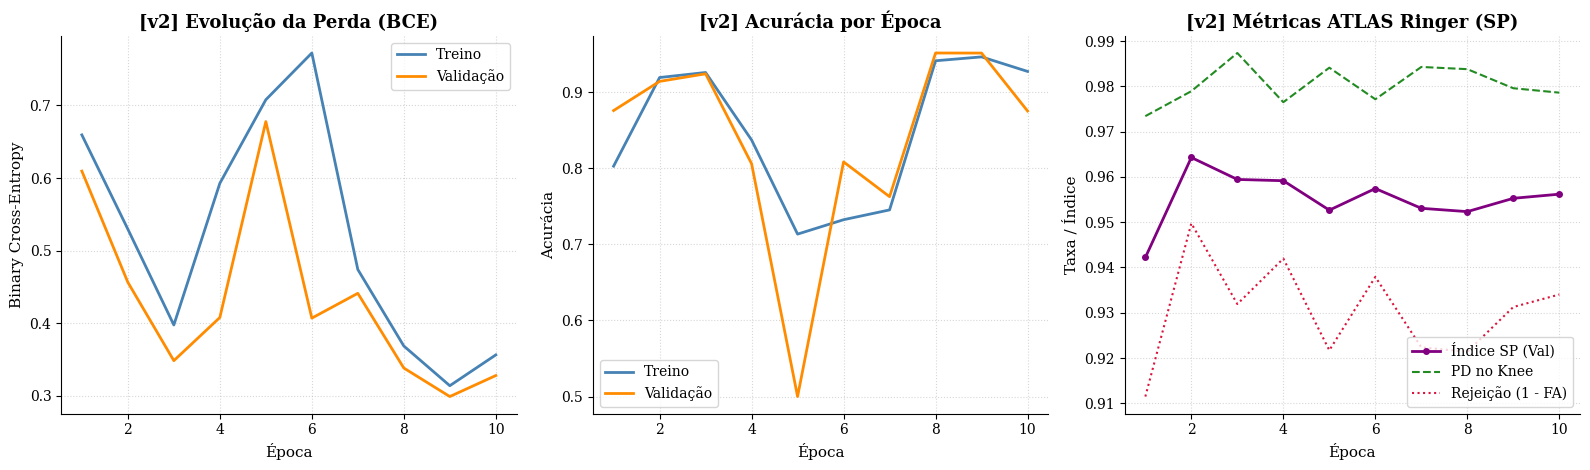

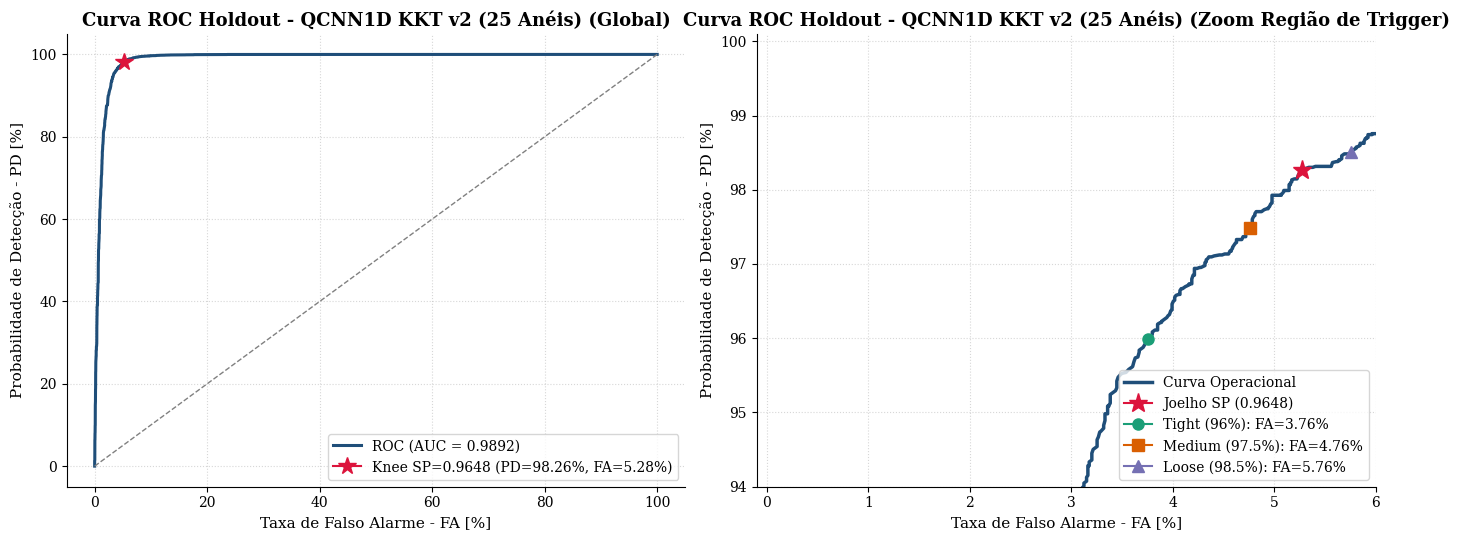

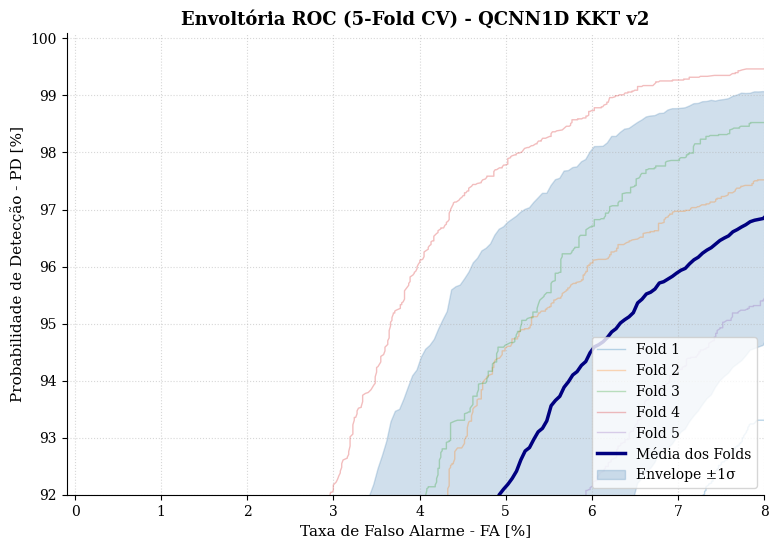

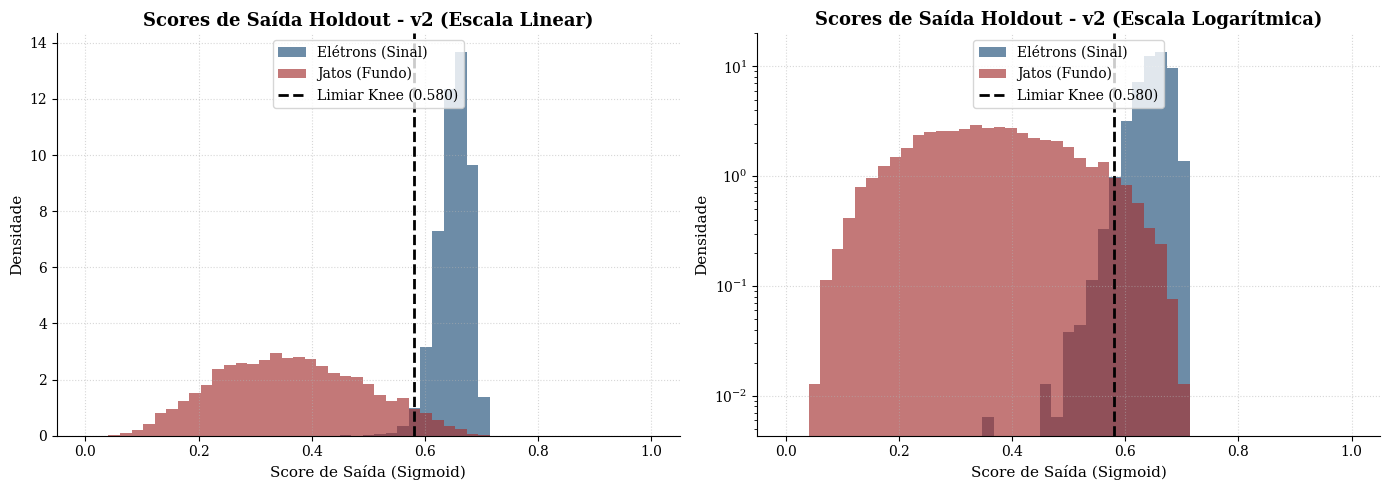

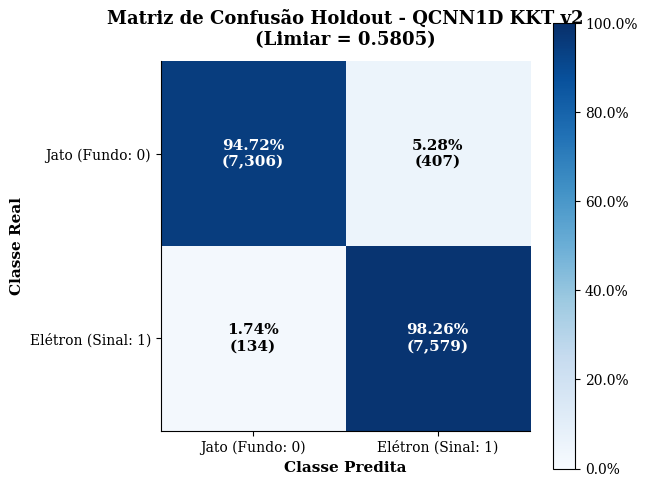

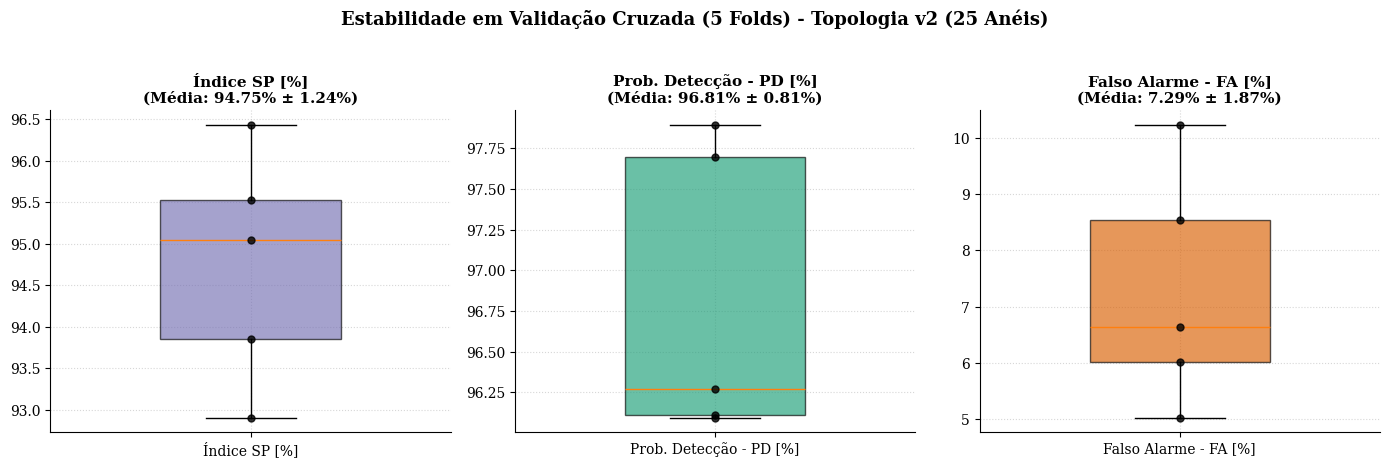

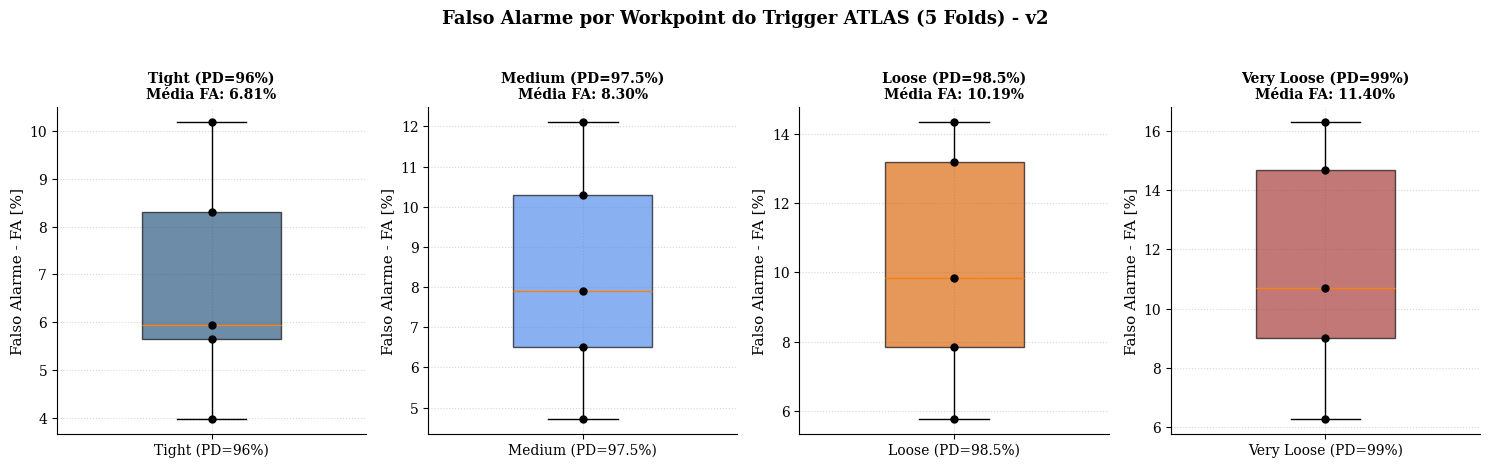

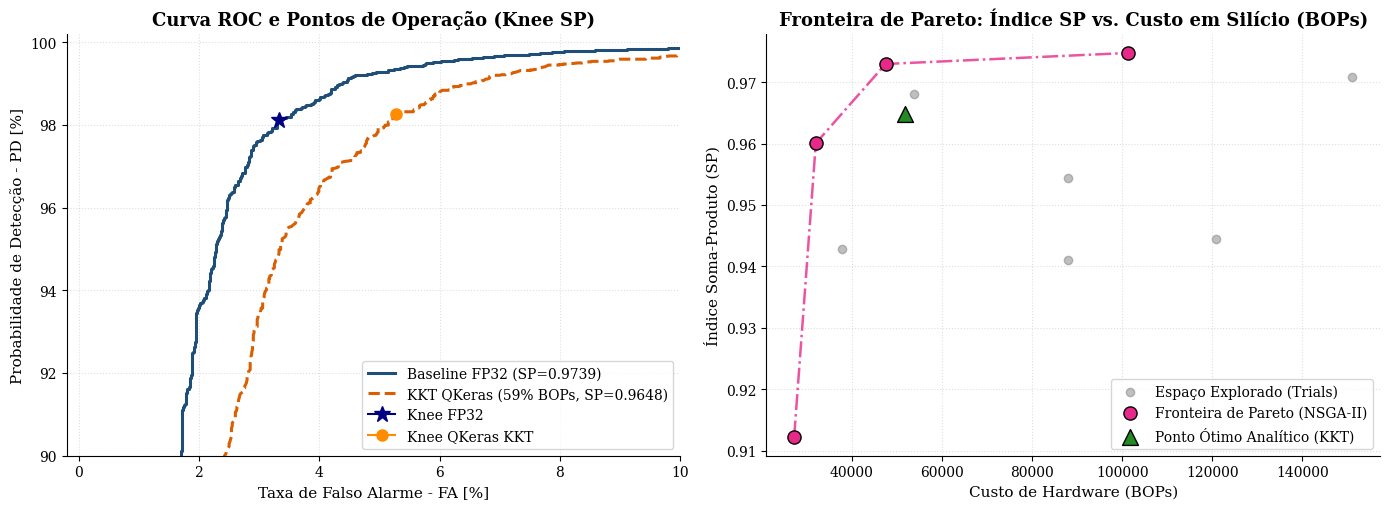

In [7]:
# 1. Curvas de Aprendizado da Melhor Execução
p_lc = plot_learning_curves(
    history_dict=best_history_dict,
    save_path=exporter.get_plot_path("learning_curves.png"),
    title_prefix=f"[v{VERSION}]",
    show=True,
)

# 2. Curva ROC do Melhor Modelo (Global + Zoom Operacional)
p_roc = plot_best_model_roc(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    sp_val=sp_ho,
    pd_knee=pd_ho,
    fa_knee=fa_ho,
    save_path=exporter.get_plot_path("roc_best_model.png"),
    title=f"Curva ROC Holdout - QCNN1D KKT v{VERSION} ({input_dim} Anéis)",
    show=True,
)

# 3. Envoltória ROC da Validação Cruzada
p_env = plot_cv_roc_envelope(
    folds_y_true=folds_y_true,
    folds_y_pred=folds_y_pred,
    save_path=exporter.get_plot_path("roc_cv_envelope.png"),
    title=f"Envoltória ROC ({N_SPLITS}-Fold CV) - QCNN1D KKT v{VERSION}",
    show=True,
)

# 4. Histograma de Scores da Saída (Linear e Log)
p_hist = plot_output_score_histogram(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    threshold_knee=thresh_ho,
    save_path=exporter.get_plot_path("output_scores_hist.png"),
    title=f"Scores de Saída Holdout - v{VERSION}",
    show=True,
)

# 5. Matriz de Confusão no Ponto de Joelho (SP Knee)
p_cm = plot_confusion_matrix_knee(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    threshold_knee=thresh_ho,
    save_path=exporter.get_plot_path("confusion_matrix_knee.png"),
    title=f"Matriz de Confusão Holdout - QCNN1D KKT v{VERSION}",
    show=True,
)

# 6. Boxplots de Estabilidade em Validação Cruzada
p_box = plot_cv_statistics_boxplots(
    cv_df=cv_df,
    save_path=exporter.get_plot_path("cv_boxplots.png"),
    title=f"Estabilidade em Validação Cruzada ({N_SPLITS} Folds) - Topologia v{VERSION} ({input_dim} Anéis)",
    show=True,
)

# 7. Boxplots de Falso Alarme por Ponto de Operação (Tight, Medium, Loose, Very Loose)
p_wp = plot_fa_per_fold_workpoints(
    folds_y_true=folds_y_true,
    folds_y_pred=folds_y_pred,
    save_path=exporter.get_plot_path("fa_per_fold_workpoints.png"),
    title=f"Falso Alarme por Workpoint do Trigger ATLAS ({N_SPLITS} Folds) - v{VERSION}",
    show=True,
)

# 8. Duelo ROC (FP32 vs QKeras KKT) e Fronteira de Pareto NSGA-II
all_sp = [t.values[0] for t in study.trials if t.values is not None]
all_bops = [t.values[1] for t in study.trials if t.values is not None]
pareto_sp = [t.values[0] for t in pareto_trials]
pareto_bops = [t.values[1] for t in pareto_trials]

p_pareto = plot_pareto_and_roc_duel(
    y_val=y_holdout,
    y_pred_fp32=y_pred_fp32_holdout,
    sp_fp32=sp_fp32_ho,
    pd_fp32=pd_fp32_ho,
    fa_fp32=fa_fp32_ho,
    y_pred_q=y_pred_holdout,
    sp_q=sp_ho,
    pd_q=pd_ho,
    fa_q=fa_ho,
    bops_ratio=kkt_result["achieved_bops"] / bops_uniform_8bit,
    all_bops=all_bops,
    all_sp=all_sp,
    pareto_bops=pareto_bops,
    pareto_sp=pareto_sp,
    kkt_bops=float(hw_qkeras_kkt["total_bops"]),
    save_path=exporter.get_plot_path("pareto_and_roc_duel.png"),
    show=True,
)


## 7. Verificação da Árvore de Artefatos Gerada (Padrão Jubiaba) e Tabela Síntese

Listamos todos os arquivos exportados na hierarquia de diretórios e consolidamos a tabela final para o artigo.


In [8]:
print(f"=== Árvore de Artefatos Gerada em: {exporter.base_dir} ===")
for root, dirs, files in os.walk(exporter.base_dir):
    level = root.replace(exporter.base_dir, "").count(os.sep)
    indent = "  " * level
    folder_name = os.path.basename(root) if level > 0 else f"v{VERSION}/"
    print(f"{indent}├── {folder_name}/")
    subindent = "  " * (level + 1)
    for f_name in sorted(files):
        f_path = os.path.join(root, f_name)
        size_kb = os.path.getsize(f_path) / 1024.0
        print(f"{subindent}└── {f_name} ({size_kb:.1f} KB)")

summary_df = pd.DataFrame([
    {
        "Topologia": f"v{VERSION} ({input_dim} Anéis)",
        "Modelo": "Baseline FP32",
        "Precisão": "Float32",
        "SP Holdout [%]": f"{sp_fp32_ho*100:.2f}%",
        "PD Holdout [%]": f"{pd_fp32_ho*100:.2f}%",
        "FA Holdout [%]": f"{fa_fp32_ho*100:.2f}%",
        "MACs": f"{hw_fp32['total_macs']:,}",
        "BOPs": f"{hw_fp32['total_bops']:,}",
        "Bits de Pesos": f"{hw_fp32['total_weight_bits']:,}",
    },
    {
        "Topologia": f"v{VERSION} ({input_dim} Anéis)",
        "Modelo": "QCNN1D KKT (Melhor Fold)",
        "Precisão": f"Conv:{kkt_weights_bits['conv1d_1']}b | Dense:{kkt_weights_bits['dense_1']}b | Out:{kkt_weights_bits['output_dense']}b",
        "SP Holdout [%]": f"{sp_ho*100:.2f}%",
        "PD Holdout [%]": f"{pd_ho*100:.2f}%",
        "FA Holdout [%]": f"{fa_ho*100:.2f}%",
        "MACs": f"{hw_qkeras_kkt['total_macs']:,}",
        "BOPs": f"{hw_qkeras_kkt['total_bops']:,}",
        "Bits de Pesos": f"{hw_qkeras_kkt['total_weight_bits']:,}",
    },
])
display(summary_df)


=== Árvore de Artefatos Gerada em: /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2 ===
├── v2//
  ├── saved_models/
    └── best_model.keras (49.8 KB)
    └── best_model.onnx (0.7 KB)
    └── model_v2_f1_r1.keras (49.8 KB)
    └── model_v2_f2_r1.keras (49.8 KB)
    └── model_v2_f3_r1.keras (49.8 KB)
    └── model_v2_f4_r1.keras (49.8 KB)
    └── model_v2_f5_r1.keras (49.8 KB)
  ├── plots/
    └── confusion_matrix_knee.png (159.1 KB)
    └── cv_boxplots.png (237.2 KB)
    └── fa_per_fold_workpoints.png (224.9 KB)
    └── learning_curves.png (467.5 KB)
    └── output_scores_hist.png (185.8 KB)
    └── pareto_and_roc_duel.png (388.7 KB)
    └── rings_profile_v2.png (233.2 KB)
    └── roc_best_model.png (349.2 KB)
    └── roc_cv_envelope.png (269.6 KB)
  ├── history/
    └── history.json (1.8 KB)
    └── training_history.csv (1.4 KB)
  ├── metadata/
    └── cross_validation_results.csv (0.7 KB)
    └── kkt_allocation_results

,Topologia,Modelo,Precisão,SP Holdout [%],PD Holdout [%],FA Holdout [%],MACs,BOPs,Bits de Pesos
0,v2 (25 Anéis),Baseline FP32,Float32,97.39%,98.11%,3.33%,"1,376","88,064","6,536"
1,v2 (25 Anéis),QCNN1D KKT (Melhor Fold),Conv:3b | Dense:6b | Out:8b,96.48%,98.26%,5.28%,"1,376","51,776","4,824"
